# 03 - Results and interpretation

Final held-out test results for PatchCore and PaDiM on MVTec AD `transistor`, an
independent recomputation of pixel-level metrics from the saved anomaly maps, representative
inspections, and the limitations of this study.

In [1]:
from pathlib import Path
import io
import json
import sys

import pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display

CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(path for path in CANDIDATES if (path / "configs" / "config.yaml").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from industrial_defect.config import configured_path, load_config

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 160)


def show(path, width=1100):
    # Display a saved figure at a bounded width so notebook outputs stay small.
    pil = PILImage.open(path)
    ratio = min(1.0, width / pil.width)
    if ratio < 1.0:
        pil = pil.resize((width, int(pil.height * ratio)), PILImage.Resampling.LANCZOS)
    buffer = io.BytesIO()
    pil.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


config = load_config(PROJECT_ROOT / "configs" / "config.yaml")
category = str(config["data"]["category"])
metrics_dir = configured_path(config, "metrics_dir") / category
predictions_dir = configured_path(config, "predictions_dir") / category
figures_dir = configured_path(config, "figures_dir") / category
print("project root:", PROJECT_ROOT.name)
print(f"category: {category}")

project root: transistor
category: transistor


## Final metrics

In [2]:
models = ("patchcore", "padim")
rows = []
for model in models:
    metrics = json.loads((metrics_dir / f"{model}_metrics.json").read_text())
    rows.append(
        {
            "model": model,
            "image AUROC": metrics["image_metrics"]["image_auroc"],
            "image AP": metrics["image_metrics"]["image_average_precision"],
            "image F1": metrics["image_metrics"]["image_f1"],
            "image P": metrics["image_metrics"]["image_precision"],
            "image R": metrics["image_metrics"]["image_recall"],
            "pixel AUROC": metrics["pixel_metrics"]["pixel_auroc"],
            "pixel AP": metrics["pixel_metrics"]["pixel_average_precision"],
            "pixel F1": metrics["pixel_metrics"]["pixel_f1"],
            "AUPRO": metrics["pro_metrics"]["pro_auc"],
        }
    )
final_metrics = pd.DataFrame(rows).set_index("model")
final_metrics.round(4)

,image AUROC,image AP,image F1,image P,image R,pixel AUROC,pixel AP,pixel F1,AUPRO
model,,,,,,,,,
patchcore,0.9883,0.9867,0.9041,1.0,0.825,0.9644,0.6334,0.6005,0.9442
padim,0.9950,0.9929,0.7500,1.0,0.600,0.9829,0.7443,0.6681,0.9894


## Independent verification from saved maps

The per-image anomaly maps stored in `reports/predictions/<category>/<model>_test_maps.npz` are re-scored
here with the same metric functions used by the evaluation script. This checks that the
reported pixel metrics and AUPRO follow from the stored maps and calibrated thresholds, not
from the reporting code path alone.

In [3]:
import gc

import numpy as np

from industrial_defect.evaluation import pixel_level_metrics, pro_metric

verification_rows = []
for model in models:
    stored = json.loads((metrics_dir / f"{model}_metrics.json").read_text())
    payload = np.load(predictions_dir / f"{model}_test_maps.npz")
    maps = payload["maps"]
    masks = payload["masks"]
    labels = payload["labels"]
    pixel = pixel_level_metrics(
        list(maps), list(masks), stored["pixel_metrics"]["pixel_threshold"]
    )
    pro = pro_metric(
        list(maps[labels == 1]),
        list(masks[labels == 1]),
        list(maps[labels == 0]),
        fpr_limit=stored["pro_metrics"]["pro_fpr_limit"],
        steps=stored["pro_metrics"]["pro_steps"],
    )
    verification_rows.append(
        {
            "model": model,
            "pixel_auroc_diff": abs(pixel["pixel_auroc"] - stored["pixel_metrics"]["pixel_auroc"]),
            "pixel_ap_diff": abs(
                pixel["pixel_average_precision"] - stored["pixel_metrics"]["pixel_average_precision"]
            ),
            "pixel_f1_diff": abs(pixel["pixel_f1"] - stored["pixel_metrics"]["pixel_f1"]),
            "pro_auc_diff": abs(pro["pro_auc"] - stored["pro_metrics"]["pro_auc"]),
            "gt_regions": pro["pro_regions"],
        }
    )
    del payload, maps, masks, labels
    gc.collect()
verification = pd.DataFrame(verification_rows).set_index("model")
display(verification.round(10))
metric_diffs = verification.drop(columns=["gt_regions"])
print("all numeric differences < 1e-6:", bool((metric_diffs < 1e-6).all().all()))

,pixel_auroc_diff,pixel_ap_diff,pixel_f1_diff,pro_auc_diff,gt_regions
model,,,,,
patchcore,0.0,0.0,0.0,0.0,44
padim,0.0,0.0,0.0,0.0,44


all numeric differences < 1e-6: True


## Per-defect detection and localisation

In [4]:
rows = []
for model in models:
    error = json.loads((metrics_dir / f"{model}_error_analysis.json").read_text())
    for defect, stats in error["per_defect_type"].items():
        rows.append(
            {
                "model": model,
                "defect_type": defect,
                "images": stats["images"],
                "detected": stats["detected"],
                "detection_rate": stats["detection_rate"],
                "localisation_rate": stats["localization_rate"],
            }
        )
per_defect = pd.DataFrame(rows)
per_defect.pivot(index="defect_type", columns="model", values=["detected", "localisation_rate"])

detected           localisation_rate          
model           padim patchcore             padim patchcore
defect_type                                                
bent_lead         6.0       9.0               1.0       1.0
cut_lead          4.0       7.0               1.0       1.0
damaged_case      4.0       9.0               1.0       1.0
misplaced        10.0       8.0               1.0       1.0

## Representative inspections

patchcore - true positive


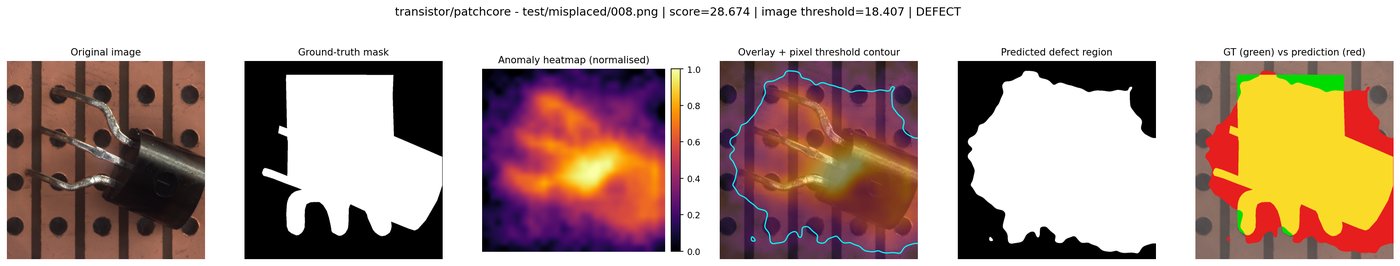

padim - true positive


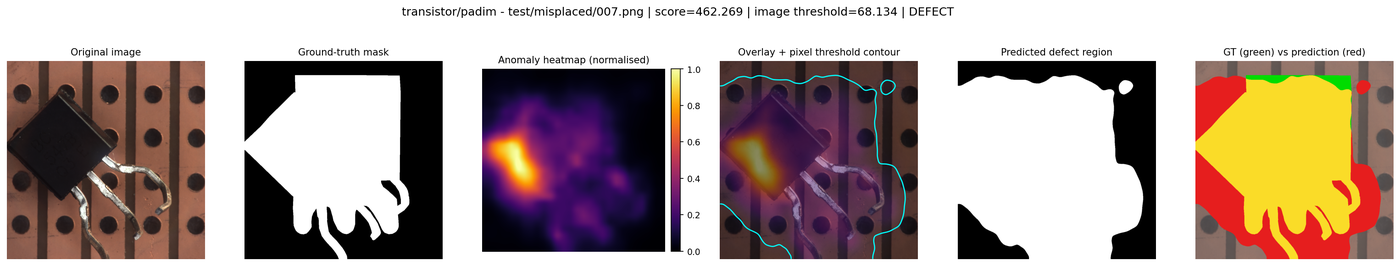

In [5]:
for model in models:
    path = figures_dir / model / "inspection_true_positive.png"
    print(f"{model} - true positive")
    show(path, width=1400)

patchcore - false negatives


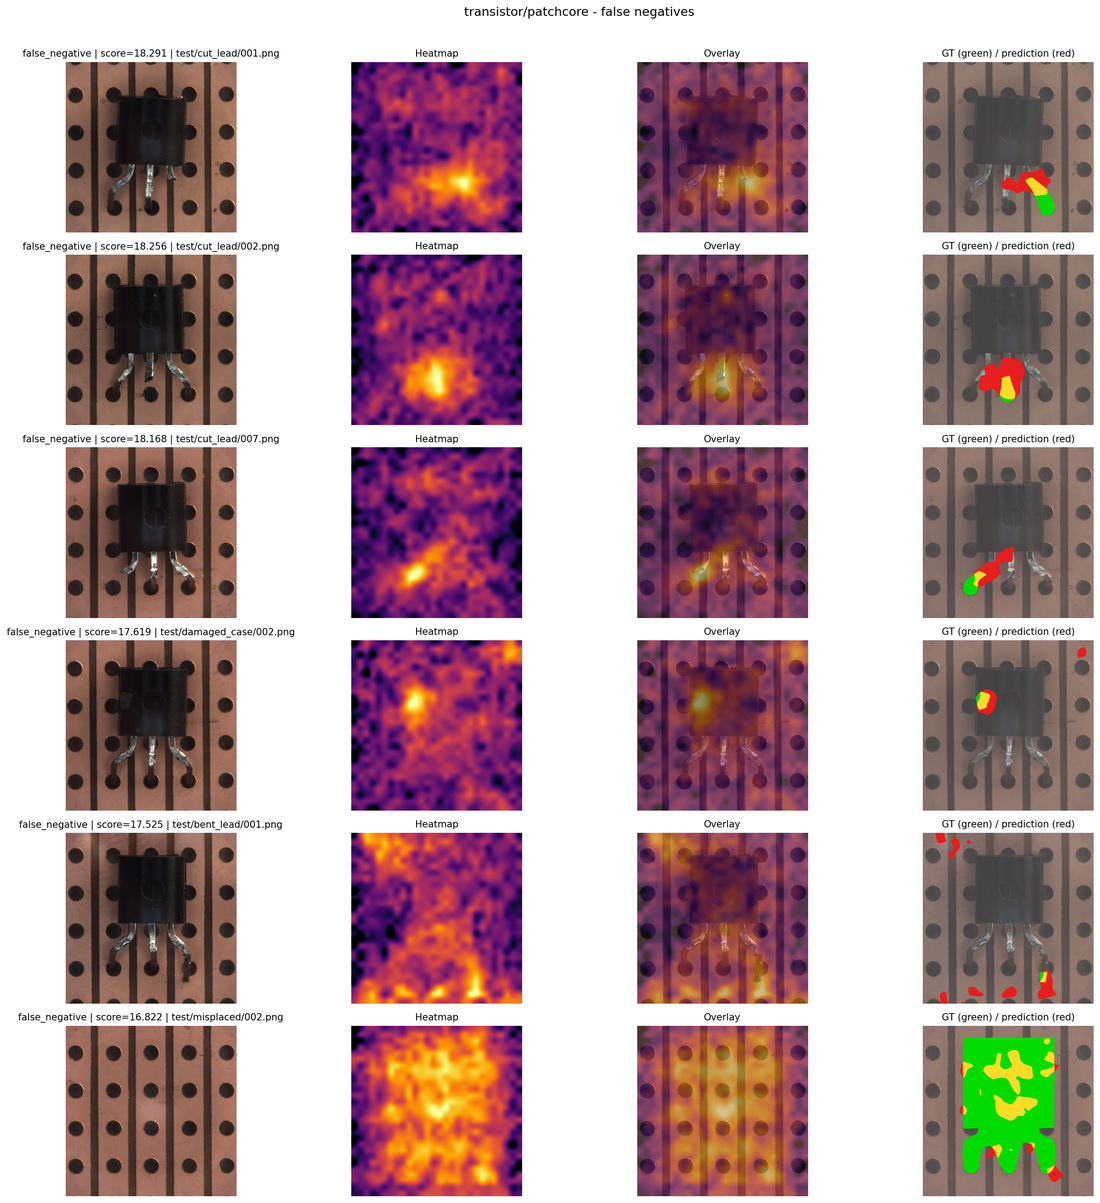

padim - false negatives


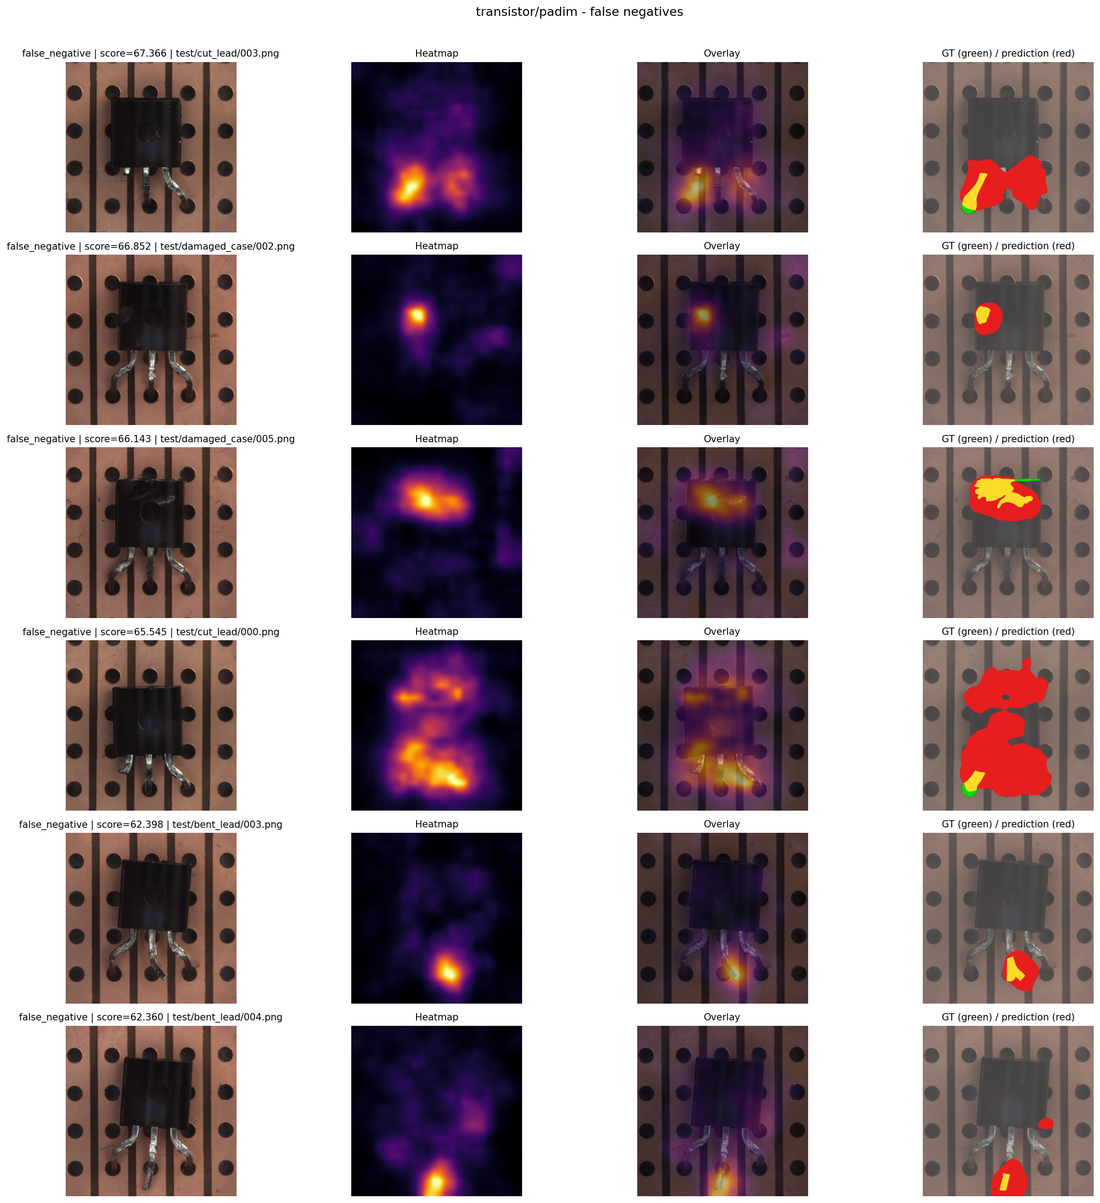

In [6]:
for model in models:
    path = figures_dir / model / "false_negatives.png"
    print(f"{model} - false negatives")
    show(path, width=1100)

## What the results show

- **Image-level ranking is close to saturated on this category.** Both models exceed 0.98
  AUROC and AP; the remaining errors are concentrated in the smallest defects and in the
  threshold operating point, not in gross ranking failures.
- **PatchCore is the stronger operating-point detector here**, catching 33/40 anomalies
  with zero false positives on 60 normal images. Its normal-validation maximum sits close
  to the threshold, so this margin should not be assumed to transfer to other data.
- **PaDiM is the stronger ranker and localiser by AUROC/AP/AUPRO**, but its calibrated
  threshold detects only 24/40 anomalies at the same normal-only false-positive budget.
  This is a calibration/operating-point effect, not a ranking failure.
- **Pixel recall is high, pixel precision is lower.** Every anomalous image has some
  predicted pixels overlapping the ground truth for both models, but predicted regions are
  wider than the masks. Pixel F1 (0.60-0.67) is therefore much lower than pixel AUROC
  (0.96-0.98).
- **Large defects dominate pooled pixel metrics.** `misplaced` masks cover about 40% of the
  image; lead and case defects are ~0.2-5%. Pooled pixel AUROC/AP mostly reflect the large
  type, while AUPRO area-weights regions and is a fairer summary of small-region
  localisation.

## Limitations

- **Category scope.** This notebook covers the `transistor` category only, and these
  numbers apply to `transistor` only. The project scope is final and frozen at exactly six
  MVTec AD categories (`transistor`, `cable`, `leather`, `bottle`, `capsule`, `grid`); the
  other nine (`carpet`, `hazelnut`, `metal_nut`, `pill`, `screw`, `tile`, `toothbrush`,
  `wood`, `zipper`) are intentionally out of scope and are not downloaded, trained,
  evaluated or served. Each supported category is trained, calibrated and evaluated
  independently, so results do not transfer across categories, and this is **not** a
  complete 15-category benchmark.
- **Small evaluation set.** 40 anomalies and 60 normals make metric confidence intervals
  wide, and the image threshold comes from 43 normal calibration images.
- **Threshold estimate is coarse.** The p99 image threshold has an empirical validation FPR
  of about 2.3% (1/43); pixel p99.5 is 0.5% by construction. Production drift is not modelled.
- **Pixel metrics use 512x512 evaluation.** Ground-truth masks are downsampled with max
  pooling, and the same resolution is used for calibration, so reported pixel numbers are
  not directly comparable to papers that evaluate at 1024x1024.
- **AUPRO is capped at FPR 0.3** and uses normal-image score quantiles as thresholds.
- **No robustness study.** Lighting, camera or fixture changes are out of scope; the
  prototype should be re-calibrated per deployment.
- **Research prototype.** Not a certified production inspection system.

## Reproducing this record

```bash
python scripts/01_validate_dataset.py
python scripts/02_explore_dataset.py
python scripts/03_prepare_data.py
python scripts/04_train.py --model both
python scripts/05_calibrate.py
python scripts/06_evaluate.py
pytest
streamlit run app/streamlit_app.py
python scripts/07_predict.py --input <image-or-folder> --model both
```

The commands above act on the active category (`transistor` in `configs/config.yaml`).
To inspect another supported category without changing the default, pass
`--category <name>` to the dataset/training/calibration/evaluation scripts; categories
outside the frozen six are rejected before any artifact is loaded.